# Annotation Experiment – Analysis (Group 1)

Offensiveness annotation of **216 tweets** (topics BLM, Covid-19, Elections2020) in 7 batches with Arbiter:
two annotators label each tweet, disagreements are discussed, and disagreements that remain go to the expert.

| Section | Task |
|---|---|
| 1 | Workflow statistics |
| 2–3 | Agreement before vs. after discussion, overall and per batch |
| 4 | Prevalence of offensiveness, overall and per topic |
| 5 | Agreement with the original annotation |
| 6 | Why we deviate on BLM |

**Final label** = expert label if there is one, else the label after discussion, else the initial label.

**Metrics.** Percentage agreement (PA) and three chance-corrected metrics of the form $(P_o - P_e)/(1 - P_e)$:
- **Bennett, Alpert and Goldstein's S** (our group's metric): $P_e = 1/k$; for $k = 2$ categories $S = 2 P_o - 1$.
  Used for the agreement between our annotators (sections 2–3, slide 3).
- **Gwet's AC1**: $P_e = 2\pi(1-\pi)$ with $\pi$ = mean share of "offensive" over both raters.
  It stays stable when one class is rare – here only about 10 % of the tweets are offensive.
  Used for the comparison with the original (section 5, slide 5).
- **Cohen's κ** (for reference): $P_e = p_1 p_2 + (1-p_1)(1-p_2)$ with $p_i$ = share of "offensive" of rater $i$.
  With rare positives $P_e$ is close to 1, so κ is low even when PA is high ("kappa paradox").

## 0. Setup

In [1]:
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when run from annotation_experiment/ (Jupyter default) or the repo root
BASE = next(p for p in [".", "annotation_experiment"] if os.path.isdir(os.path.join(p, "annotated_data")))
FIG_DIR = os.path.join(BASE, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

ANNOTATORS = ["group1_annotator1", "group1_annotator2"]
EXPERT = "group1_expert"
TOPICS = ["BLM", "Covid-19", "Elections2020"]

# Colours of the slides
LIGHT, DARK, ACCENT = "#6f9fdc", "#2f6db5", "#c26a1e"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

In [2]:
def label(entries, user):
    '''1 = user assigned 'Offensiveness', 0 = user assigned no label, NaN = no entry of this user.'''
    for e in entries:
        if e["user"] == user:
            return int("Offensiveness" in e["labels"])
    return np.nan

def after_discussion(row, user):
    '''Label after discussion; the initial label if the tweet was not discussed.'''
    lab = label(row["labels_discussion"], user)
    return label(row["labels_annotation"], user) if np.isnan(lab) else lab

def final_label(row):
    '''Expert label if there is one, else the (agreed) label after discussion.'''
    lab = label(row["labels_expert"], EXPERT)
    return after_discussion(row, ANNOTATORS[0]) if np.isnan(lab) else lab

def agreement(a, b):
    '''Percentage agreement, Bennett's S, Gwet's AC1 and Cohen's kappa for two binary label vectors.

    A chance-corrected metric is undefined when its chance agreement is 1 (both annotators
    used the same single label on every item): it is reported as NaN instead of 0/0.'''
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    pa = np.mean(a == b)
    pi = (a.mean() + b.mean()) / 2
    pe_ac1 = 2 * pi * (1 - pi)
    pe_kappa = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return pd.Series({"PA": pa, "S": 2 * pa - 1,
                      "AC1": np.nan if np.isclose(pe_ac1, 1.0) else (pa - pe_ac1) / (1 - pe_ac1),
                      "kappa": np.nan if np.isclose(pe_kappa, 1.0) else (pa - pe_kappa) / (1 - pe_kappa)})

### Load and check the data

In [3]:
rows = []
for f in sorted(glob.glob(os.path.join(BASE, "annotated_data", "batch_*.jsonl"))):
    with open(f, encoding="utf-8") as fp:
        rows += [json.loads(line) for line in fp if line.strip()]
df = pd.DataFrame(rows)  # same table as arbiter_analysis.load.annotations(), without the extra dependency

df["topic"] = df["text"].str.extract(r"^\[(.+?)\]", expand=False)
for i, user in enumerate(ANNOTATORS, start=1):
    df[f"before_A{i}"] = df["labels_annotation"].apply(label, user=user)
    df[f"after_A{i}"] = df.apply(after_discussion, axis=1, user=user)
df["final"] = df.apply(final_label, axis=1)
df["discussed"] = df["labels_discussion"].str.len() > 0
df["expert"] = df["labels_expert"].str.len() > 0

label_cols = ["before_A1", "before_A2", "after_A1", "after_A2", "final"]
assert len(df) == 216 and df["text_id"].is_unique
assert df["batch_number"].value_counts().sort_index().tolist() == [12] + [34] * 6
assert set(df["topic"]) == set(TOPICS)
assert df[label_cols].notna().all().all(), "every tweet needs a label from both annotators"
assert (df["discussed"] == (df["before_A1"] != df["before_A2"])).all(), "exactly the disagreements are discussed"
assert (df["expert"] == (df["after_A1"] != df["after_A2"])).all(), "exactly the unresolved cases go to the expert"
df[label_cols] = df[label_cols].astype(int)

n = len(df)
print(f"{n} tweets | per batch {df['batch_number'].value_counts().sort_index().to_dict()} "
      f"| per topic {df['topic'].value_counts().to_dict()} | all checks passed")

216 tweets | per batch {1: 12, 2: 34, 3: 34, 4: 34, 5: 34, 6: 34, 7: 34} | per topic {'BLM': 78, 'Elections2020': 75, 'Covid-19': 63} | all checks passed


## 1. Workflow statistics

,tweets,share
annotated,216,100.0%
discussed (initial disagreement),28,13.0%
expert decision (still disagreed),4,1.9%


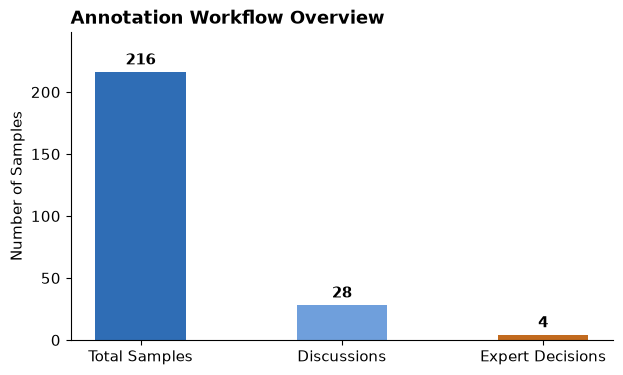

In [4]:
workflow = pd.DataFrame({"tweets": [n, df["discussed"].sum(), df["expert"].sum()]},
                        index=["annotated", "discussed (initial disagreement)", "expert decision (still disagreed)"])
workflow["share"] = (workflow["tweets"] / n).map("{:.1%}".format)
display(workflow)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Total Samples", "Discussions", "Expert Decisions"], workflow["tweets"], 0.45, color=[DARK, LIGHT, ACCENT])
ax.bar_label(bars, padding=3, fontweight="bold")
ax.set_ylim(0, n * 1.15)
ax.set_ylabel("Number of Samples")
ax.set_title("Annotation Workflow Overview")
save(fig, "fig_workflow_overview.png")
plt.show()

## 2. Agreement before vs. after discussion

A2 (before),0,1,All
A1 (before),,,
0,179,18,197
1,10,9,19
All,189,27,216


A2 (after),0,1,All
A1 (after),,,
0,195,2,197
1,2,17,19
All,197,19,216


'Offensive' before discussion: A1 19 times, A2 27 times (of 216)


,before,after
PA,0.870,0.981
S,0.741,0.963
AC1,0.840,0.978
kappa,0.321,0.885


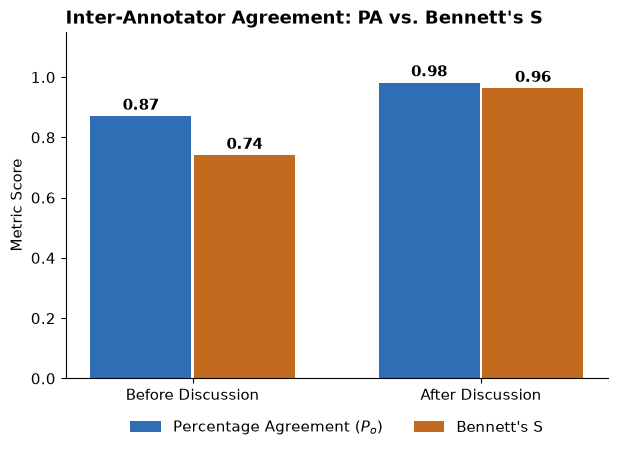

In [5]:
for stage in ["before", "after"]:
    display(pd.crosstab(df[f"{stage}_A1"], df[f"{stage}_A2"], margins=True,
                        rownames=[f"A1 ({stage})"], colnames=[f"A2 ({stage})"]))
print(f"'Offensive' before discussion: A1 {df['before_A1'].sum()} times, A2 {df['before_A2'].sum()} times (of {n})")

overall = pd.DataFrame({stage: agreement(df[f"{stage}_A1"], df[f"{stage}_A2"]) for stage in ["before", "after"]})
display(overall.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
for offset, metric, color, name in [(-0.18, "PA", DARK, "Percentage Agreement ($P_o$)"), (0.18, "S", ACCENT, "Bennett's S")]:
    bars = ax.bar(x + offset, overall.loc[metric], 0.35, color=color, label=name)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontweight="bold")
ax.set_xticks(x, ["Before Discussion", "After Discussion"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Metric Score")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.set_title("Inter-Annotator Agreement: PA vs. Bennett's S")
save(fig, "fig_agreement_pa_s.png")
plt.show()

Discussion resolved 24 of the 28 disagreements: PA rises from 0.87 to 0.98, Bennett's S from 0.74 to 0.96 (AC1: 0.84 → 0.98).
Before discussion, A2 labelled "offensive" more often than A1 (27 vs. 19 times).
κ is much lower than S and AC1 before discussion (0.32) because only about 10 % of the tweets are offensive:
κ's expected agreement is already 0.81, so the few disagreements on offensive tweets weigh heavily.

## 3. Agreement per batch

,n,discussed,expert,PA before,S before,AC1 before,κ before,PA after,S after,AC1 after,prevalence (final)
batch_number,,,,,,,,,,,
1,12,2,0,0.833,0.667,0.803,0.000,1.000,1.000,1.000,0.167
2,34,6,2,0.824,0.647,0.751,0.407,0.941,0.882,0.921,0.118
3,34,4,1,0.882,0.765,0.860,0.277,0.971,0.941,0.966,0.059
4,34,4,0,0.882,0.765,0.860,0.277,1.000,1.000,1.000,0.059
5,34,2,0,0.941,0.882,0.934,0.469,1.000,1.000,1.000,0.088
6,34,7,1,0.794,0.588,0.733,0.105,0.971,0.941,0.966,0.088
7,34,3,0,0.912,0.824,0.892,0.532,1.000,1.000,1.000,0.059


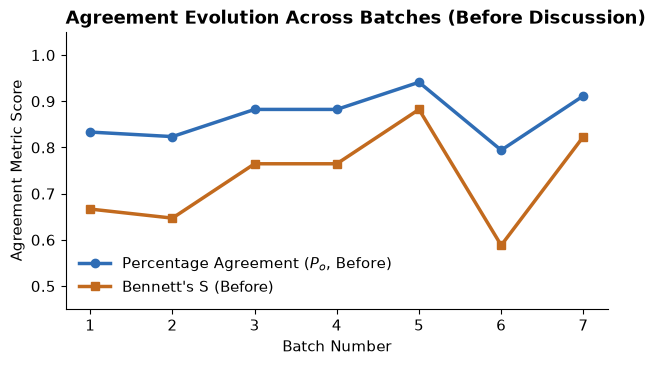

In [6]:
def batch_summary(g):
    before, after = agreement(g["before_A1"], g["before_A2"]), agreement(g["after_A1"], g["after_A2"])
    return pd.Series({"n": len(g), "discussed": g["discussed"].sum(), "expert": g["expert"].sum(),
                      "PA before": before["PA"], "S before": before["S"], "AC1 before": before["AC1"],
                      "κ before": before["kappa"], "PA after": after["PA"], "S after": after["S"],
                      "AC1 after": after["AC1"], "prevalence (final)": g["final"].mean()})

cols = label_cols + ["discussed", "expert"]
per_batch = df.groupby("batch_number")[cols].apply(batch_summary).astype({"n": int, "discussed": int, "expert": int})
display(per_batch.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(per_batch.index, per_batch["PA before"], "o-", color=DARK, lw=2.5, label="Percentage Agreement ($P_o$, Before)")
ax.plot(per_batch.index, per_batch["S before"], "s-", color=ACCENT, lw=2.5, label="Bennett's S (Before)")
ax.set_xlabel("Batch Number")
ax.set_ylabel("Agreement Metric Score")
ax.set_ylim(0.45, 1.05)
ax.legend(loc="lower left")
ax.set_title("Agreement Evolution Across Batches (Before Discussion)")
save(fig, "fig_batch_evolution.png")
plt.show()

Agreement before discussion varies between S 0.59 and 0.88 without a steady trend. The lowest value is batch 6
(7 discussions), with political critique edge cases such as #488. After discussion, S is at least 0.88 in every batch.

## 4. Prevalence of offensiveness

,n,offensive,before,final
topic,,,,
BLM,78,1,4.5%,1.3%
Covid-19,63,6,11.1%,9.5%
Elections2020,75,11,16.7%,14.7%
All,216,18,10.6%,8.3%


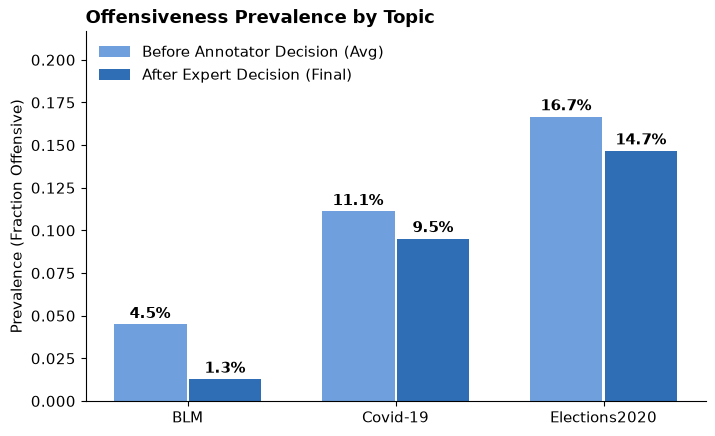

In [7]:
df["before_mean"] = df[["before_A1", "before_A2"]].mean(axis=1)
prev = df.groupby("topic").agg(n=("final", "size"), offensive=("final", "sum"),
                               before=("before_mean", "mean"), final=("final", "mean"))
prev.loc["All"] = [n, df["final"].sum(), df["before_mean"].mean(), df["final"].mean()]
display(prev.astype({"n": int, "offensive": int}).assign(before=prev["before"].map("{:.1%}".format),
                                                         final=prev["final"].map("{:.1%}".format)))

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(TOPICS))
for offset, col, color, name in [(-0.18, "before", LIGHT, "Before Annotator Decision (Avg)"),
                                 (0.18, "final", DARK, "After Expert Decision (Final)")]:
    bars = ax.bar(x + offset, prev.loc[TOPICS, col], 0.35, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in prev.loc[TOPICS, col]], padding=2, fontweight="bold")
ax.set_xticks(x, TOPICS)
ax.set_ylim(0, prev.loc[TOPICS, "before"].max() * 1.3)
ax.set_ylabel("Prevalence (Fraction Offensive)")
ax.legend(loc="upper left")
ax.set_title("Offensiveness Prevalence by Topic")
save(fig, "fig_prevalence_by_topic.png")
plt.show()

In the end 8.3 % of the tweets are offensive (18 of 216). Elections2020 has the highest share (14.7 %), BLM the lowest (1.3 %).
Discussion lowered the share in every topic, most strongly in BLM (4.5 % → 1.3 %).

## 5. Agreement with the original annotation

In [8]:
orig = pd.read_csv(os.path.join(BASE, "original_data", "original_final_labels.csv"), index_col=0)
cmp = df.merge(orig.rename(columns={"final_label": "original"}), on="text", how="left", validate="one_to_one")
assert cmp["original"].notna().all(), "every tweet needs an original label"

ours = agreement(cmp["final"], cmp["original"])
baseline = agreement(np.zeros(n), cmp["original"])  # trivial annotator that never says 'offensive'
print(f"PA {ours['PA']:.1%} ({(cmp['final'] == cmp['original']).sum()} of {n}) | AC1 {ours['AC1']:.2f} "
      f"(baseline 'never offensive': {baseline['AC1']:.2f}) | kappa {ours['kappa']:.2f}")
display(pd.crosstab(cmp["final"], cmp["original"], rownames=["ours"], colnames=["original"], margins=True))

def vs_original(g):
    a = agreement(g["final"], g["original"])
    return pd.Series({"n": len(g), "PA": a["PA"], "AC1": a["AC1"], "κ": a["kappa"],
                      "offensive ours": g["final"].sum(), "offensive original": g["original"].sum(),
                      "missed": ((g["original"] == 1) & (g["final"] == 0)).sum(),
                      "extra": ((g["original"] == 0) & (g["final"] == 1)).sum()})

by_topic = cmp.groupby("topic")[["final", "original"]].apply(vs_original)
display(by_topic.astype({c: int for c in ["n", "offensive ours", "offensive original", "missed", "extra"]}).round(3))

PA 91.7% (198 of 216) | AC1 0.90 (baseline 'never offensive': 0.89) | kappa 0.50


original,0,1,All
ours,,,
0,187,11,198
1,7,11,18
All,194,22,216


,n,PA,AC1,κ,offensive ours,offensive original,missed,extra
topic,,,,,,,,
BLM,78,0.936,0.930,0.270,1,6,5,0
Covid-19,63,0.921,0.903,0.571,6,7,3,2
Elections2020,75,0.893,0.861,0.539,11,9,3,5


PA (91.7 %) and AC1 (0.90) look high, but a trivial annotator that never says "offensive" already reaches AC1 0.89
against the original, because only 10 % of the tweets are offensive. κ = 0.50 shows that agreement on the offensive
tweets is only moderate: we found 11 of the 22 tweets the original marks as offensive, and 7 of our 18 offensive labels
are not offensive in the original. We miss most in BLM (5 of 6, κ = 0.27) and over-label Elections2020 (5 extra).

## 6. Why we deviate on BLM

In [9]:
blm = cmp[cmp["topic"] == "BLM"]
missed = blm[(blm["original"] == 1) & (blm["final"] == 0)]
found = blm[(blm["original"] == 1) & (blm["final"] == 1)]
print(f"BLM: {int(blm['original'].sum())} offensive in the original | found by us: {found['text_id'].tolist()} "
      f"| missed: {len(missed)}")
with pd.option_context("display.max_colwidth", None):
    display(missed[["text_id", "batch_number", "before_A1", "before_A2", "discussed", "text"]])

# How did discussions end per topic?
discussed = cmp[cmp["discussed"]]
display(discussed.groupby("topic").agg(discussed=("final", "size"), ended_offensive=("final", "sum"),
                                       original_offensive=("original", "sum")))

# BLM examples in the codebook: (not offensive, offensive)
def blm_examples(path):
    not_offensive, offensive = open(path, encoding="utf-8").read().split("#### Offensive")
    return not_offensive.count("[BLM]"), offensive.count("[BLM]")

print("BLM examples in our codebook (not offensive, offensive):",
      blm_examples(os.path.join(BASE, "annotated_data", "codebook.md")))

BLM: 6 offensive in the original | found by us: [549] | missed: 5


,text_id,batch_number,before_A1,before_A2,discussed,text
47,230,3,0,0,False,[BLM]: The hits just keep coming...what a turd.
56,239,3,0,0,False,"[BLM]: You don’t give a fuck about George Floyd bro, stop fucking acting like you care. You don’t give a shit about us! You just want our votes, but guess what honey, you’re not about to get mine, and whoever supports you can go kiss somebody else ass cause mine is too good for y’all 😂 <url>"
168,499,6,1,0,True,[BLM]: Look at this! Scum #londonriots #londonprotests
172,503,6,0,0,False,"[BLM]: THAT MAN KNEW EXACTLY WTF HE WAS DOING! NOTHING WAS ACCIDENTAL! IF IT WAS ACCIDENTAL HE SHOULD'VE STOPPED THE FIRST TIME GEORGE FLOYD SAID ""I CAN'T BREATHE""! FUCK YOUR ""THIRD DEGREE"" #RAISETHEDEGREE #RaiseTheCharge #RAISETHEDEGRE"
210,575,7,0,0,False,"[BLM]: Duck... you’re right, this MF will get off because of stupidity. Crap, here comes another riot oh I mean protest."


,discussed,ended_offensive,original_offensive
topic,,,
BLM,5,0,1
Covid-19,8,3,3
Elections2020,15,6,6


BLM examples in our codebook (not offensive, offensive): (4, 1)


Of the 6 BLM tweets the original marks as offensive, we found only 1 (#549). The 5 we missed all contain vulgar language
("turd", "fuck", "Scum", "WTF", "MF"). Three reasons:

1. **Shared blind spot.** 4 of the 5 were "not offensive" for both of us, so they were never discussed.
   With only two annotators, one shared slip is enough – e.g. #575: I (A1) overlooked what "MF" means.
2. **Discussions ended lenient.** All 5 BLM discussions ended "not offensive"
   (Covid-19: 3 of 8, Elections2020: 6 of 15 ended offensive).
3. **The codebook leans lenient on BLM.** 4 of its 5 BLM examples are "not offensive" despite insults
   ("Y'all mfs … stupid asses"). We never revised them, and "speculative offensiveness" rules out unclear targets
   ("what a turd").

BLM has the highest agreement with the original (93.6 %) but the lowest κ (0.27).

## Key results

- **Workflow:** 216 tweets, 28 discussions (13.0 %), 4 expert decisions (1.9 %).
- **Agreement A1–A2** (before → after discussion): PA 0.87 → 0.98, Bennett's S 0.74 → 0.96 (AC1 0.84 → 0.98, κ 0.32 → 0.88).
- **Prevalence** (final): 8.3 % overall; Elections2020 14.7 %, Covid-19 9.5 %, BLM 1.3 %.
- **Agreement with the original:** PA 91.7 %, AC1 0.90 (trivial baseline 0.89), κ 0.50; we found 11 of the 22 offensive tweets.
- **BLM:** we found only 1 of 6 offensive tweets; the 5 misses all contain vulgar language, and 4 of them were never
  discussed because both annotators agreed.